# CrusherCal, afirmación BS-1: validación con datos retenidos y una banda predictiva calibrada, medida, incluido dónde falla el protocolo dentro de la muestra

**Pregunta:** ¿Llega el protocolo con datos retenidos de CrusherCal a conclusiones sobre el modelo del HP500 que el protocolo dentro de la muestra del estado del arte se equivoca, y está calibrada su banda predictiva de 80 por ciento hasta donde diez muestreos pueden decirlo?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** el notebook 03 del tema 05-real-surveys y los notebooks 01 y 02 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook usted puede:

- enunciar la afirmación BS-1 del documento de diseño del producto y decir qué evidencia la sostendría y cuál la refutaría;
- mostrar dos conclusiones que el protocolo dentro de la muestra del estado del arte alcanza y que el protocolo con datos retenidos revierte;
- probar la robustez de la habilidad en tonelaje, sobre subconjuntos aleatorios de los muestreos;
- leer la banda predictiva de 80 por ciento, su semiancho y su cobertura, y decir hasta dónde pueden calibrarla diez muestreos;
- declarar qué no puede mostrar este notebook de la afirmación.

## Preparación

Numpy y matplotlib. Las probabilidades binomiales de la prueba de cobertura usan solo la biblioteca estándar.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son los mismos constructores, más `math` de la biblioteca estándar para los coeficientes binomiales.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import math

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500 y los documentos versionados derivados de ellos. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` y `data/derived/hp500/loo.json`.

La celda lee los archivos y reconstruye en vivo el documento de CrusherCal.

In [2]:
# Reconstruya en vivo la columna vertebral y el documento de CrusherCal desde la tabla de muestreos; deben ser los versionados
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("el documento de CrusherCal reconstruido es igual al versionado:", doc == committed, "| muestreos:", doc["n"])

el documento de CrusherCal reconstruido es igual al versionado: True | muestreos: 10


## Método

**La afirmación.** El documento de diseño del producto lista la afirmación BS-1: una validación fuera de la muestra de un modelo de chancador calibrado con datos de muestreos industriales abiertos, con una banda predictiva calibrada y controles preregistrados, entregada en el navegador del lector. Va más allá de dos estados del arte: el modelo del HP500 de Rocha et al. (2024; https://doi.org/10.3390/min14090919), ajustado y juzgado dentro de la muestra con los mismos diez muestreos, y los sustitutos aprendidos de modelos de conminución (Koh et al., 2021; https://doi.org/10.1016/j.mineng.2021.107026), que no informan paridad industrial con datos retenidos ni incertidumbre.

La afirmación puede fallar de cuatro maneras, y el notebook mide cada una: los números retenidos podrían no mostrar habilidad sobre la línea base; los controles podrían superar al modelo; la habilidad podría desaparecer al remuestrear los diez muestreos; o la banda podría estar mal calibrada. La entrega en el navegador es una propiedad de la aplicación web, cubierta por sus propias pruebas, y de un notebook no puede salir evidencia sobre ella. La celda lista las entradas de la afirmación, el MAPE retenido de cada modelo y la línea base para el tonelaje.

In [3]:
# Los errores de tonelaje retenidos de los modelos y la línea base, desde el documento vivo de CrusherCal
strict = doc["loo"]["tph"]["strict"]
for name in ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean", "M1_label_shuffle"):
    print(f"{name:18s} {strict[name]['mape_pct']:6.2f} %")
print("muestreos:", doc["n"], "| configuración:", doc["config"])

M0_backbone         12.09 %
M1_residual         13.45 %
M2_freeform         12.18 %
constant_mean       18.29 %
M1_label_shuffle    25.04 %
muestreos: 10 | configuración: {'resid_clip_frac': 0.2, 'ridge_lambda': 1.0, 'features': ['cssMm', 'f80Mm'], 'targets_primary': ['tph', 'kW'], 'target_secondary': ['p80']}


## Estado del arte

El estado del arte juzga un modelo calibrado por su coincidencia con los datos a los que se ajustó (notebook 03 del tema 05). La celda pone los números dentro de la muestra de ese protocolo junto a los números retenidos de CrusherCal, para los modelos de tonelaje y para las estimaciones de potencia. Los dos casos de interés son aquellos donde la conclusión dentro de la muestra y la conclusión retenida discrepan. Para el tonelaje, el protocolo dentro de la muestra dice que la regresión sin restricciones (8,24 por ciento) es mucho mejor que la columna vertebral con su escalar reajustado (10,95); con datos retenidos empatan (12,18 y 12,09). Para la potencia, el reajuste dentro de la muestra de la forma del artículo (19,28 por ciento) supera a la media constante (22,03); con datos retenidos, la potencia de la columna vertebral (25,94) es peor que la media (24,48).

In [4]:
# Conclusiones dentro de la muestra frente a retenidas, lado a lado, para los modelos de tonelaje y para la potencia
for key, label in (("tph", "tonelaje"), ("kW", "potencia")):
    print(label)
    for name in ("M0_backbone", "M2_freeform", "constant_mean"):
        a, b = doc["loo"][key]["leaky"][name]["mape_pct"], doc["loo"][key]["strict"][name]["mape_pct"]
        print(f"  {name:14s} dentro de la muestra {a:6.2f} %   retenido {b:6.2f} %")
    mean_in, mean_out = doc["loo"][key]["leaky"]["constant_mean"]["mape_pct"], doc["loo"][key]["strict"]["constant_mean"]["mape_pct"]
    model_in, model_out = doc["loo"][key]["leaky"]["M0_backbone"]["mape_pct"], doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"]
    print(f"  columna vertebral frente a la media, dentro de la muestra y retenido: {(mean_in - model_in) / mean_in * 100:+.1f} % , {(mean_out - model_out) / mean_out * 100:+.1f} %")

tonelaje
  M0_backbone    dentro de la muestra  10.95 %   retenido  12.09 %
  M2_freeform    dentro de la muestra   8.24 %   retenido  12.18 %
  constant_mean  dentro de la muestra  16.46 %   retenido  18.29 %
  columna vertebral frente a la media, dentro de la muestra y retenido: +33.5 % , +33.9 %
potencia
  M0_backbone    dentro de la muestra  19.28 %   retenido  25.94 %
  M2_freeform    dentro de la muestra   9.46 %   retenido  14.03 %
  constant_mean  dentro de la muestra  22.03 %   retenido  24.48 %
  columna vertebral frente a la media, dentro de la muestra y retenido: +12.5 % , -6.0 %


La figura dibuja los errores dentro de la muestra y retenidos de los tres modelos para cada objetivo, como pares. Las reversiones se ven como barras que cambian de orden entre los dos paneles.

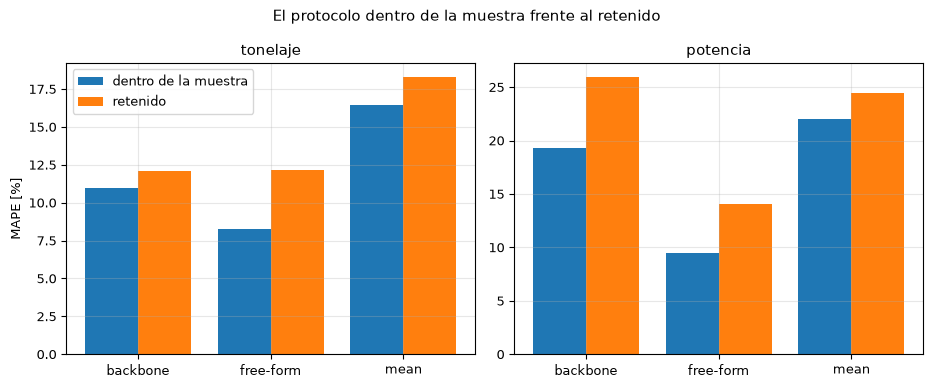

In [5]:
# Barras pareadas del error dentro de la muestra y retenido de la columna vertebral, la regresión sin restricciones y la media, por objetivo
models = ("M0_backbone", "M2_freeform", "constant_mean")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in zip(axes, ("tph", "kW"), ("tonelaje", "potencia")):
    x = np.arange(len(models))
    ax.bar(x - 0.2, [doc["loo"][key]["leaky"][m]["mape_pct"] for m in models], 0.4, label="dentro de la muestra")
    ax.bar(x + 0.2, [doc["loo"][key]["strict"][m]["mape_pct"] for m in models], 0.4, label="retenido")
    ax.set_xticks(x, ["backbone" if m == "M0_backbone" else "free-form" if m == "M2_freeform" else "mean" for m in models])
    ax.set_title(label)
axes[0].set_ylabel("MAPE [%]")
axes[0].legend()
fig.suptitle("El protocolo dentro de la muestra frente al retenido")
fig.tight_layout()
plt.show()

A la izquierda, el tonelaje: dentro de la muestra la barra de la regresión sin restricciones es mucho más baja que la de la columna vertebral, y con datos retenidos las dos tienen la misma altura, de modo que el protocolo dentro de la muestra habría recomendado abandonar la física por una regresión, una conclusión que no sobrevive a la retención. A la derecha, la potencia: dentro de la muestra la barra de la columna vertebral está bajo la de la media, y con datos retenidos está sobre ella, de modo que el protocolo dentro de la muestra habría reconocido a la forma de potencia una habilidad que no tiene. Son los casos donde el protocolo del estado del arte se equivoca, y ambos vienen de la misma causa: diez puntos dejan espacio para que un modelo con coeficientes libres ajuste lo que es ruido.

## Más allá del estado del arte

**Prueba 1, robustez de la habilidad en tonelaje.** Un conjunto de diez muestreos es una muestra. La celda sortea 200 subconjuntos aleatorios de 7 muestreos, con semilla, reconstruye la columna vertebral y la validación retenida en cada uno, y cuenta los subconjuntos donde la columna vertebral retenida supera a la media constante y donde supera a la regresión sin restricciones, para el tonelaje y para la potencia. Cada subconjunto es una prueba distinta y más pequeña de la misma afirmación.

In [6]:
# Validación retenida en 200 subconjuntos aleatorios de 7 muestreos: con qué frecuencia la columna vertebral supera a la media y a la regresión sin restricciones
rng = np.random.default_rng(2026)
wins = {"tph": [0, 0], "kW": [0, 0]}
for _ in range(200):
    chosen = sorted(rng.choice(10, 7, replace=False).tolist())
    sub = loo.build(backbone.build([surveys[j] for j in chosen], version), version)["loo"]
    for key in wins:
        wins[key][0] += sub[key]["strict"]["M0_backbone"]["mape_pct"] < sub[key]["strict"]["constant_mean"]["mape_pct"]
        wins[key][1] += sub[key]["strict"]["M0_backbone"]["mape_pct"] < sub[key]["strict"]["M2_freeform"]["mape_pct"]
for key, label in (("tph", "tonelaje"), ("kW", "potencia")):
    print(f"{label:10s} la columna vertebral supera a la media en {wins[key][0]} de 200 subconjuntos; supera a la regresión sin restricciones en {wins[key][1]}")

tonelaje   la columna vertebral supera a la media en 200 de 200 subconjuntos; supera a la regresión sin restricciones en 126
potencia   la columna vertebral supera a la media en 51 de 200 subconjuntos; supera a la regresión sin restricciones en 14


La habilidad en tonelaje es robusta: la columna vertebral supera a la media constante en los 200 subconjuntos, de modo que ninguna elección de siete muestreos la hace perder frente a la línea base. Frente a la regresión sin restricciones gana en 126 de 200 subconjuntos, una mayoría modesta, que concuerda con el empate con diez muestreos. La habilidad en potencia no es robusta: la columna vertebral supera a la media en solo 51 subconjuntos (25,5 por ciento), y la regresión sin restricciones supera a la columna vertebral en 93 por ciento de los subconjuntos. La afirmación de BS-1 es sobre el tonelaje y sobre el protocolo, y los subconjuntos miden ambos.

**Prueba 2, la banda predictiva.** CrusherCal envuelve la predicción retenida de la columna vertebral en un intervalo de 80 por ciento, $\hat y \pm 1{,}2816\,\sigma$, con $\sigma$ la desviación estándar de los residuos retenidos. La celda lee, para el tonelaje y para la potencia, el semiancho, su tamaño relativo a la medición media y la cobertura empírica, la fracción de los diez muestreos cuya medición cae dentro de su propio intervalo. La figura grafica las diez mediciones contra sus intervalos.

In [7]:
# Semiancho y cobertura de la banda de 80 % para ambos objetivos, y los muestreos que caen fuera de ella
for key, label in (("tph", "tonelaje [t/h]"), ("kW", "potencia [kW]")):
    uq = doc["loo"][key]["strict"]["uq"]
    held = np.array(doc["loo"][key]["strict"]["pred"]["M0"])
    truth = np.array(doc["loo"][key]["measured"])
    outside = [surveys[i].survey for i in np.nonzero(np.abs(truth - held) > uq["band_halfwidth"])[0]]
    print(f"{label:16s} semiancho {uq['band_halfwidth']:7.2f} ({uq['band_rel_pct']:5.2f} % de la media)  cobertura {uq['empirical_coverage']:.2f} frente a nominal {uq['nominal_coverage']:.2f}  fuera: {outside}")

tonelaje [t/h]   semiancho  238.50 (20.81 % de la media)  cobertura 0.90 frente a nominal 0.80  fuera: [1]
potencia [kW]    semiancho  105.06 (36.48 % de la media)  cobertura 0.90 frente a nominal 0.80  fuera: [7]


La figura grafica las diez mediciones contra las predicciones retenidas de la columna vertebral, con la banda dibujada en torno a cada predicción.

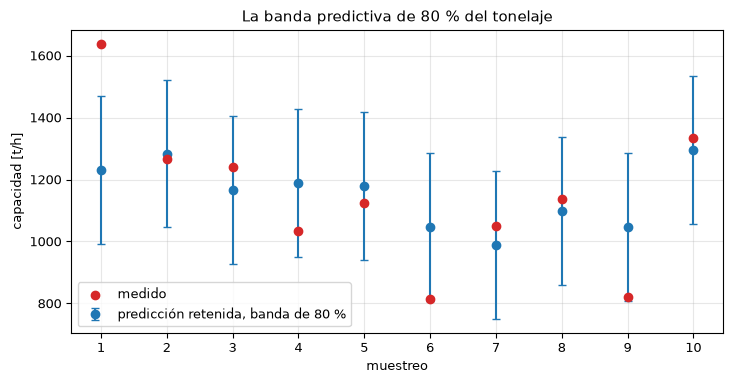

In [8]:
# Grafique las diez mediciones contra las predicciones retenidas con sus intervalos de 80 %, tonelaje
uq = doc["loo"]["tph"]["strict"]["uq"]
held = np.array(doc["loo"]["tph"]["strict"]["pred"]["M0"])
truth = np.array(doc["loo"]["tph"]["measured"])
fig, ax = plt.subplots()
ax.errorbar(range(1, 11), held, yerr=uq["band_halfwidth"], fmt="o", capsize=3, label="predicción retenida, banda de 80 %")
ax.scatter(range(1, 11), truth, color="tab:red", zorder=3, label="medido")
ax.set_xlabel("muestreo")
ax.set_xticks(range(1, 11))
ax.set_ylabel("capacidad [t/h]")
ax.set_title("La banda predictiva de 80 % del tonelaje")
ax.legend()
fig.tight_layout()
plt.show()

Nueve de los diez puntos rojos quedan dentro de su banda, y el décimo, el muestreo 1, queda sobre ella. La banda no es pequeña: su semiancho de 238,5 t/h es 20,8 por ciento del tonelaje medio medido, de modo que se le dice al usuario que el próximo muestreo estará en cualquier punto de un rango de 477 t/h, lo que es honesto para un modelo que solo conoce la abertura. Para la potencia el semiancho de 105 kW es 36,5 por ciento de la media, y la banda es más ancha que toda la dispersión de la cantidad, que es como se ve la ausencia de habilidad. La cobertura de 0,90 frente al nominal de 0,80 es la pregunta siguiente.

**Prueba 3, ¿es una cobertura de 9 de 10 consistente con 80 por ciento?** Con diez muestreos la cobertura empírica solo puede tomar los valores 0, 0,1, ... 1, así que es una estimación gruesa. Si la banda estuviera exactamente calibrada, el número de muestreos dentro seguiría una ley binomial con $n = 10$ y $p = 0{,}8$. La celda calcula la probabilidad de cada cuenta y la probabilidad de una cuenta al menos tan alta como la observada de 9, y la figura dibuja la distribución con la observación marcada.

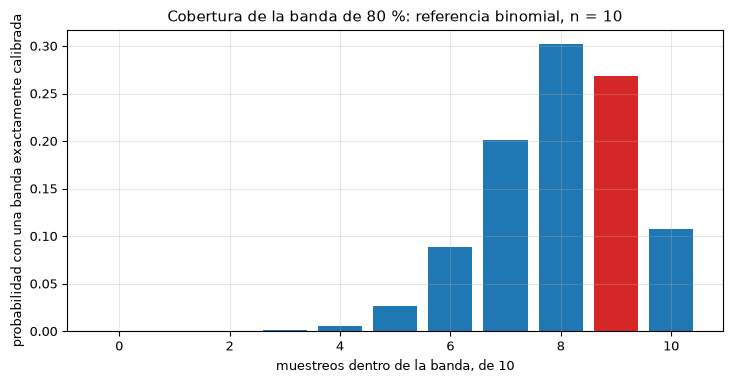

cuenta observada: 9 | P(cuenta >= observada) = 0.3758 | P(cuenta <= observada) = 0.8926


In [9]:
# Distribución binomial del número de muestreos dentro de una banda de 80 % exactamente calibrada, y la cuenta observada
pmf = [math.comb(10, k) * 0.8 ** k * 0.2 ** (10 - k) for k in range(11)]
observed = round(doc["loo"]["tph"]["strict"]["uq"]["empirical_coverage"] * 10)
fig, ax = plt.subplots()
ax.bar(range(11), pmf, color=["tab:red" if k == observed else "tab:blue" for k in range(11)])
ax.set_xlabel("muestreos dentro de la banda, de 10")
ax.set_ylabel("probabilidad con una banda exactamente calibrada")
ax.set_title("Cobertura de la banda de 80 %: referencia binomial, n = 10")
fig.tight_layout()
plt.show()
print("cuenta observada:", observed, "| P(cuenta >= observada) =", round(sum(pmf[observed:]), 4), "| P(cuenta <= observada) =", round(sum(pmf[: observed + 1]), 4))

Una cuenta de 9 tiene probabilidad de 0,268 y una cuenta de 9 o más tiene 0,376 con una banda perfectamente calibrada, de modo que la cobertura observada es el segundo resultado más probable y no es motivo de preocupación: los datos no pueden distinguir esta banda de una exactamente calibrada. Tampoco pueden distinguirla de una con cobertura verdadera de 0,65 o de 0,95, porque con diez muestreos la binomial es ancha. El enunciado honesto es que la banda es consistente con su nivel nominal y que diez muestreos no pueden establecerlo con más precisión. La figura muestra la distribución de referencia; no es una prueba de calibración.

## Resultados

**Respuesta:** sí, dentro de los límites de diez muestreos. El protocolo con datos retenidos revierte dos conclusiones del protocolo dentro de la muestra: elimina la ventaja aparente de una regresión sin restricciones sobre la columna vertebral del tonelaje (8,24 frente a 10,95 por ciento dentro de la muestra, 12,18 frente a 12,09 retenido) y elimina la habilidad aparente de la forma de potencia (19,28 frente a 22,03 por ciento dentro de la muestra, 25,94 frente a 24,48 retenido). La habilidad en tonelaje es robusta: la columna vertebral retenida supera a la media constante en 200 de 200 subconjuntos aleatorios de siete muestreos, y el control de barajado con 200 semillas lo hace solo en 5. La banda de 80 por ciento tiene un semiancho de 238,5 t/h y una cobertura de 0,90 (9 de 10), una cuenta con probabilidad 0,376 o más con calibración exacta, de modo que la banda es consistente con su nivel nominal y diez muestreos no pueden decir más.

Para la afirmación BS-1 esta es la evidencia: validación con datos retenidos con controles y una banda, medida aquí, con el fracaso del residuo acotado para superar a la columna vertebral (13,45 frente a 12,09 por ciento) informado como el nulo preregistrado que es. Lo que el notebook no muestra es la entrega de la afirmación en el navegador, que cubren las pruebas propias de la aplicación. Tampoco muestra que el modelo generalice a otro chancador o mineral: diez muestreos de una máquina no pueden. Y la potencia sigue siendo un negativo honesto, que el producto no reclama.

## Resumen

BS-1 es una afirmación sobre el método, no sobre un error menor: la validación con datos retenidos, los controles corridos las veces suficientes y una banda predictiva cambian lo que se puede concluir de diez muestreos. Medidos aquí, eliminan dos conclusiones falsas del protocolo dentro de la muestra, confirman que la columna vertebral del tonelaje tiene una habilidad robusta y muestran una banda consistente con su cobertura nominal, mientras la potencia queda sin predecir. El tema siguiente pasa a los modelos aprendidos y a la misma disciplina aplicada a ellos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026